# Разведочный анализ исходных данных (EDA)

## Цель ноутбука
Определить, как выглядят исходные логовые и KPI-данные: их структура, статистические свойства, временная организация и содержательные особенности.
Результат notebook — воспроизводимый аналитический каркас для последующей подготовки данных.

## Аналитические вопросы
1. Какова структура исходных источников и базовое качество данных?
2. Как распределён логовый поток во времени и по меткам класса?
3. Как устроено распределение шаблонов логов и их статистические признаки?
4. Как содержательно выглядят типичные записи в нормальных и аномальных эпизодах?
5. Каковы структурные и статистические свойства KPI-модальности как самостоятельного источника?
6. Какое временное разрешение KPI сохраняет предсбойную динамику при оконной агрегации?
7. Насколько покрытие KPI на шкале логов связано с положительным классом?
8. Какая стратегия восстановления log episodes лучше объясняет связь логов с KPI-сценариями?
9. Какие рабочие гипотезы агрегации в окнах следуют непосредственно из EDA?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")

ROOT = Path.cwd()
LOG_PATH = ROOT / "log_csv" / "drain_labeled.csv"
KPI_ROOT = ROOT / "kpi_csv"

log_df = pd.read_csv(LOG_PATH, usecols=["Timestamp", "Content", "DrainTemplate", "Label"])
log_df["Timestamp"] = pd.to_numeric(log_df["Timestamp"], errors="coerce")
log_df["Label"] = pd.to_numeric(log_df["Label"], errors="coerce").fillna(0).astype(int)
log_df = log_df.dropna(subset=["Timestamp"]).copy()
log_df["Timestamp"] = log_df["Timestamp"].astype("int64")
log_df["timestamp_dt"] = pd.to_datetime(log_df["Timestamp"], unit="s", utc=True)

kpi_all_csv = list(KPI_ROOT.rglob("*.csv"))
kpi_raw_csv = [p for p in kpi_all_csv if not p.stem.endswith("-labeled") and not p.stem.endswith("-intersect")]
kpi_labeled_csv = [p for p in kpi_all_csv if p.stem.endswith("-labeled")]
kpi_intersect_csv = [p for p in kpi_all_csv if p.stem.endswith("-intersect")]
kpi_apps = sorted([p for p in KPI_ROOT.iterdir() if p.is_dir()])
kpi_scenario_dirs = sorted([sc for app in kpi_apps for sc in app.iterdir() if sc.is_dir()])


def scenario_type(name: str) -> str:
    return "нормальный" if name.lower().startswith("normal") else "отказной"

## 1. Структура источников и базовый контроль качества
Сначала фиксируем паспорт данных и технические свойства, которые важны для любой последующей агрегации.

In [2]:
passport_df = pd.DataFrame(
    [
        {
            "Источник": "Логи (drain_labeled.csv)",
            "Единица наблюдения": "строка лог-сообщения",
            "Объём": f"{len(log_df):,}".replace(",", " "),
            "Ключевые поля": "Timestamp, DrainTemplate, Content, Label",
            "Временной диапазон": f"{log_df['timestamp_dt'].min()} — {log_df['timestamp_dt'].max()}",
        },
        {
            "Источник": "KPI (директория kpi_csv/)",
            "Единица наблюдения": "измерение серии (series, timestamp, value, label)",
            "Объём": f"{len(kpi_all_csv):,} CSV".replace(",", " "),
            "Ключевые поля": "series, timestamp, value, label",
            "Временной диапазон": "переменный по сценарию",
        },
        {
            "Источник": "Структура KPI-каталога",
            "Единица наблюдения": "сценарий (приложение/сценарий)",
            "Объём": f"{len(kpi_scenario_dirs):,} сценариев в {len(kpi_apps)} приложениях".replace(",", " "),
            "Ключевые поля": "cpu, memstat, iostat, netstat",
            "Временной диапазон": "задаётся для каждого сценария отдельно",
        },
    ]
)

display(passport_df)

,Источник,Единица наблюдения,Объём,Ключевые поля,Временной диапазон
0,Логи (drain_labeled.csv),строка лог-сообщения,1 048 575,"Timestamp, DrainTemplate, Content, Label",2021-11-29 03:55:29+00:00 — 2021-12-03 03:47:52+00:00
1,KPI (директория kpi_csv/),"измерение серии (series, timestamp, value, label)",5 876 CSV,"series, timestamp, value, label",переменный по сценарию
2,Структура KPI-каталога,сценарий (приложение/сценарий),587 сценариев в 21 приложениях,"cpu, memstat, iostat, netstat",задаётся для каждого сценария отдельно


### Интерпретация результата

- **Что показано:** сводный паспорт источников, их объёмов и единиц наблюдения.
- **Что наблюдается:** логовая и KPI-модальности имеют разную структуру данных и разный уровень детализации по времени.
- **Локальный вывод:** до агрегации в окна источники необходимо рассматривать как разные представления процесса, а не как одинаковые таблицы.
- **Почему это важно для ВКР:** корректная постановка EDA начинается с явного описания объекта исследования, иначе последующая статистика теряет интерпретируемость.

In [3]:
def count_unsorted_kpi_files(raw_files: list[Path]) -> tuple[int, int, int]:
    checked = 0
    unsorted = 0
    parse_errors = 0

    for csv_file in raw_files:
        try:
            tmp = pd.read_csv(csv_file, usecols=["series", "timestamp"])
        except Exception:
            parse_errors += 1
            continue

        tmp["timestamp"] = pd.to_datetime(tmp["timestamp"], errors="coerce", utc=True)
        tmp = tmp.dropna(subset=["timestamp"])
        if tmp.empty:
            continue

        checked += 1
        file_unsorted = False
        for _, group in tmp.groupby("series", sort=False):
            if not group["timestamp"].is_monotonic_increasing:
                file_unsorted = True
                break
        if file_unsorted:
            unsorted += 1

    return checked, unsorted, parse_errors


kpi_checked, kpi_unsorted, kpi_parse_errors = count_unsorted_kpi_files(kpi_raw_csv)

quality_df = pd.DataFrame(
    [
        {
            "Проверка": "Пропуски в логах (все столбцы)",
            "Результат": int(log_df[["Timestamp", "Content", "DrainTemplate", "Label"]].isna().sum().sum()),
        },
        {
            "Проверка": "Дубликаты логов по (Timestamp, Content)",
            "Результат": int(log_df.duplicated(subset=["Timestamp", "Content"]).sum()),
        },
        {
            "Проверка": "Нарушения монотонности Timestamp в логах",
            "Результат": int((log_df["Timestamp"].diff() < 0).sum()),
        },
        {
            "Проверка": "KPI-файлы raw (проверено)",
            "Результат": int(kpi_checked),
        },
        {
            "Проверка": "KPI-файлы с неупорядоченным временем внутри series",
            "Результат": int(kpi_unsorted),
        },
        {
            "Проверка": "KPI-файлы с ошибкой чтения обязательных полей",
            "Результат": int(kpi_parse_errors),
        },
    ]
)

display(quality_df)

,Проверка,Результат
0,Пропуски в логах (все столбцы),0
1,"Дубликаты логов по (Timestamp, Content)",312480
2,Нарушения монотонности Timestamp в логах,1220
3,KPI-файлы raw (проверено),2348
4,KPI-файлы с неупорядоченным временем внутри series,0
5,KPI-файлы с ошибкой чтения обязательных полей,0


### Интерпретация результата

- **Что показано:** технический контроль полноты, дубликатов и временного порядка.
- **Что наблюдается:** в логах присутствуют дубликаты и локальные перестановки времени, тогда как KPI-серии внутри файлов упорядочены стабильно.
- **Локальный вывод:** для логов обязательны удаление дубликатов и явная сортировка по времени перед оконной агрегацией.
- **Почему это важно для ВКР:** воспроизводимость экспериментального контура зависит от строгих правил предобработки уже на этапе EDA.

## 2. Временной профиль логового потока и баланс классов
Переходим к описанию динамики логов во времени и редкости аномальных событий.

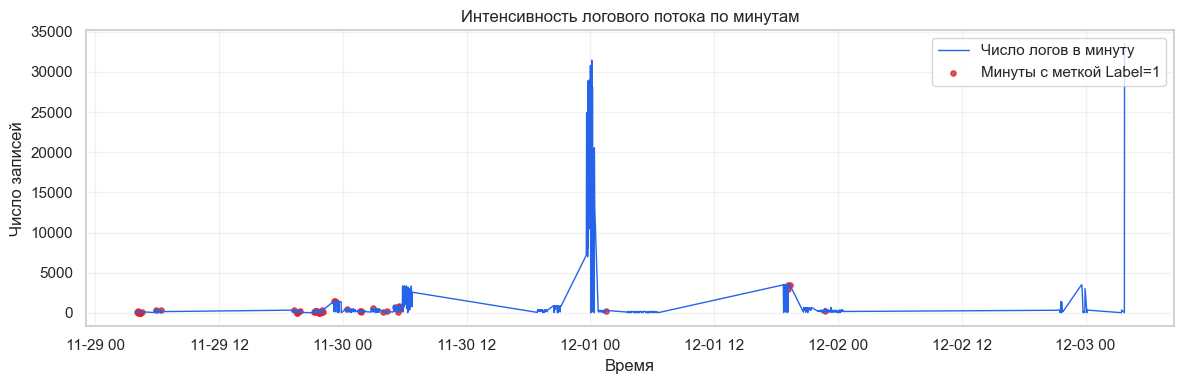

In [4]:
minute_df = (
    log_df.assign(minute=log_df["timestamp_dt"].dt.floor("min"))
    .groupby("minute", as_index=True)
    .agg(
        log_count=("Label", "size"),
        anomaly_count=("Label", "sum"),
        unique_templates=("DrainTemplate", "nunique"),
    )
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(minute_df.index, minute_df["log_count"], color="#2563eb", linewidth=1.0, label="Число логов в минуту")

anomaly_minutes = minute_df[minute_df["anomaly_count"] > 0]
if not anomaly_minutes.empty:
    ax.scatter(
        anomaly_minutes.index,
        anomaly_minutes["log_count"],
        color="#dc2626",
        s=14,
        alpha=0.8,
        label="Минуты с меткой Label=1",
    )

ax.set_title("Интенсивность логового потока по минутам")
ax.set_xlabel("Время")
ax.set_ylabel("Число записей")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Интерпретация результата

- **Что показано:** временной ряд интенсивности логов с отмеченными минутами, где присутствуют аномальные записи.
- **Что наблюдается:** поток логов выраженно нестационарен: периоды высокой и низкой активности чередуются, а аномальные минуты занимают малую долю шкалы времени.
- **Локальный вывод:** при построении признаков по времени необходимо учитывать неоднородность нагрузки, а не предполагать равномерный поток.
- **Почему это важно для ВКР:** выбор длины окна и способа нормализации должен опираться на фактическую динамику логов.

In [5]:
rows_total = len(log_df)
rows_positive = int(log_df["Label"].sum())

second_level = log_df.groupby("Timestamp")["Label"].max()
minute_level = minute_df["anomaly_count"].gt(0).astype(int)

balance_df = pd.DataFrame(
    [
        {
            "Уровень агрегации": "Строка лога",
            "Число объектов": rows_total,
            "Положительный класс": rows_positive,
            "Доля положительного класса": rows_positive / rows_total,
        },
        {
            "Уровень агрегации": "Секунда (max label внутри секунды)",
            "Число объектов": int(len(second_level)),
            "Положительный класс": int(second_level.sum()),
            "Доля положительного класса": float(second_level.mean()),
        },
        {
            "Уровень агрегации": "Минута (наличие хотя бы одной аномалии)",
            "Число объектов": int(len(minute_level)),
            "Положительный класс": int(minute_level.sum()),
            "Доля положительного класса": float(minute_level.mean()),
        },
    ]
)

balance_df["Доля положительного класса"] = balance_df["Доля положительного класса"].map(lambda x: f"{x:.4f}")
display(balance_df)

,Уровень агрегации,Число объектов,Положительный класс,Доля положительного класса
0,Строка лога,1048575,575,0.0005
1,Секунда (max label внутри секунды),14721,96,0.0065
2,Минута (наличие хотя бы одной аномалии),898,54,0.0601


### Интерпретация результата

- **Что показано:** дисбаланс классов на трёх уровнях агрегации (строка, секунда, минута).
- **Что наблюдается:** положительный класс остаётся редким даже после укрупнения единицы наблюдения.
- **Локальный вывод:** данные соответствуют задаче обнаружения редких событий, а не задаче сбалансированной бинарной классификации.
- **Почему это важно для ВКР:** дальнейшие этапы должны использовать метрики и протоколы, устойчивые к редкому положительному классу.

## 3. Распределение шаблонов логов и статистические признаки текста
Проверяем, как распределены шаблоны по частоте и насколько они разнообразны по длине и структуре.

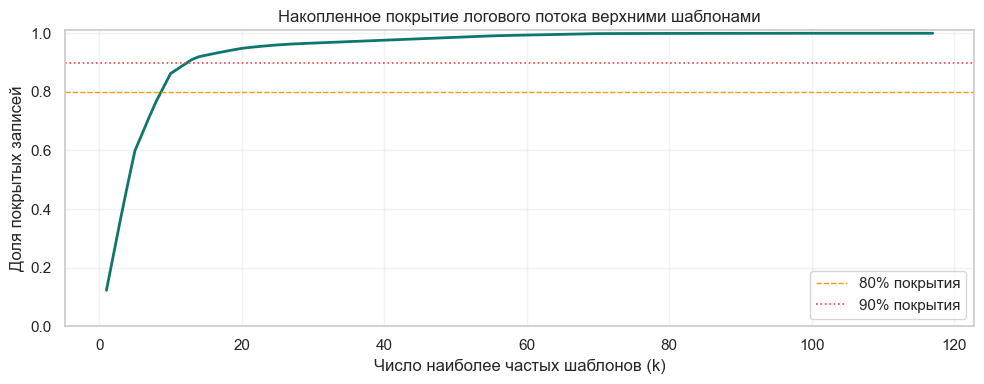

In [6]:
template_counts = log_df["DrainTemplate"].value_counts()
cum_coverage = template_counts.cumsum() / template_counts.sum()
coverage_df = pd.DataFrame({"k": np.arange(1, len(cum_coverage) + 1), "coverage": cum_coverage.values})

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(coverage_df["k"], coverage_df["coverage"], color="#0f766e", linewidth=2)
ax.axhline(0.8, color="#f59e0b", linestyle="--", linewidth=1, label="80% покрытия")
ax.axhline(0.9, color="#ef4444", linestyle=":", linewidth=1.2, label="90% покрытия")
ax.set_title("Накопленное покрытие логового потока верхними шаблонами")
ax.set_xlabel("Число наиболее частых шаблонов (k)")
ax.set_ylabel("Доля покрытых записей")
ax.set_ylim(0, 1.01)
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Интерпретация результата

- **Что показано:** кривая накопленного покрытия записей при добавлении наиболее частых шаблонов.
- **Что наблюдается:** существенная доля потока объясняется ограниченным числом шаблонов, при этом сохраняется хвост редких событий.
- **Локальный вывод:** распределение шаблонов имеет концентрированное ядро и редкий хвост, что важно для выбора схемы кодирования текста.
- **Почему это важно для ВКР:** EDA подтверждает необходимость сочетать устойчивые частотные признаки и обработку редких паттернов.

In [7]:
drain_text = log_df["DrainTemplate"].astype(str)
char_len = drain_text.str.len()
token_len = drain_text.str.split().str.len()

normal_templates = set(log_df.loc[log_df["Label"] == 0, "DrainTemplate"].unique())
anomaly_templates = set(log_df.loc[log_df["Label"] == 1, "DrainTemplate"].unique())

template_stats_df = pd.DataFrame(
    [
        {"Показатель": "Уникальных DrainTemplate", "Значение": int(template_counts.shape[0])},
        {"Показатель": "Покрытие top-10 шаблонов", "Значение": f"{template_counts.head(10).sum() / len(log_df):.4f}"},
        {"Показатель": "Шаблонов с частотой <= 100", "Значение": int((template_counts <= 100).sum())},
        {"Показатель": "Медианная длина шаблона (символы)", "Значение": float(char_len.median())},
        {"Показатель": "95-й перцентиль длины шаблона (символы)", "Значение": float(char_len.quantile(0.95))},
        {"Показатель": "Медианная длина шаблона (токены)", "Значение": float(token_len.median())},
        {"Показатель": "Пересечение шаблонов между Label=0 и Label=1", "Значение": int(len(normal_templates & anomaly_templates))},
    ]
)

display(template_stats_df)

,Показатель,Значение
0,Уникальных DrainTemplate,117
1,Покрытие top-10 шаблонов,0.8624
2,Шаблонов с частотой <= 100,46
3,Медианная длина шаблона (символы),39.0
4,95-й перцентиль длины шаблона (символы),119.0
5,Медианная длина шаблона (токены),8.0
6,Пересечение шаблонов между Label=0 и Label=1,0


### Интерпретация результата

- **Что показано:** агрегированные статистики словаря шаблонов и их текстовой формы.
- **Что наблюдается:** шаблоны компактны по длине, но неоднородны по частоте; присутствуют специфические паттерны аномальных эпизодов.
- **Локальный вывод:** логовые шаблоны пригодны для статистического и содержательного анализа как структурированный текстовый источник.
- **Почему это важно для ВКР:** это создаёт основание для дальнейшей оконной агрегации логов с интерпретируемыми признаками.

## 4. Качественный просмотр логовых сообщений
Количественные распределения дополняем качественным разбором наиболее характерных шаблонов.

In [8]:
def top_templates_by_label(label_value: int, class_name: str, top_n: int = 12) -> pd.DataFrame:
    vc = log_df.loc[log_df["Label"] == label_value, "DrainTemplate"].value_counts().head(top_n)
    out = vc.rename_axis("DrainTemplate").reset_index(name="Частота")
    out["Класс"] = class_name
    out["Доля внутри класса"] = out["Частота"] / max(1, (log_df["Label"] == label_value).sum())
    return out[["Класс", "DrainTemplate", "Частота", "Доля внутри класса"]]


top_normal = top_templates_by_label(0, "Норма", top_n=10)
top_anomaly = top_templates_by_label(1, "Аномалия", top_n=10)
top_templates_df = pd.concat([top_normal, top_anomaly], ignore_index=True)
top_templates_df["Доля внутри класса"] = top_templates_df["Доля внутри класса"].map(lambda x: f"{x:.4f}")

display(top_templates_df)

,Класс,DrainTemplate,Частота,Доля внутри класса
0,Норма,Got assigned task <*>,128821,0.1229
1,Норма,Finished task <*> in stage <*> (TID <*> <*> bytes result sent <*> <*>,128821,0.1229
2,Норма,Running task <*> in stage <*> (TID <*>,128821,0.1229
3,Норма,Found block <*> <*>,123235,0.1176
4,Норма,Block <*> stored as <*> in memory (estimated size <*> <*> free <*> MiB),118524,0.1131
5,Норма,Getting <*> <*> <*> non-empty blocks including <*> <*> <*> local and 0 (0.0 B) host-local and <*> <*> <*> remote blocks,60069,0.0573
6,Норма,Started <*> remote fetches in <*> ms,60069,0.0573
7,Норма,Don't have map outputs for shuffle <*> fetching them,57089,0.0545
8,Норма,Started reading broadcast variable <*> with <*> pieces (estimated total size <*> MiB),49406,0.0471
9,Норма,Reading broadcast variable <*> took <*> ms,49406,0.0471


### Интерпретация результата

- **Что показано:** наиболее частые шаблоны отдельно для нормального и аномального классов.
- **Что наблюдается:** аномальный класс описывается более узким набором повторяющихся шаблонов, чем нормальный.
- **Локальный вывод:** аномальные эпизоды имеют выраженные повторяющиеся семантические маркеры в логах.
- **Почему это важно для ВКР:** качественная интерпретируемость шаблонов необходима для прозрачного объяснения дальнейших признаков.

In [9]:
first_anomaly_time = log_df.loc[log_df["Label"] == 1, "timestamp_dt"].min()

fragment_df = (
    log_df[
        (log_df["timestamp_dt"] >= first_anomaly_time - pd.Timedelta(seconds=30))
        & (log_df["timestamp_dt"] <= first_anomaly_time + pd.Timedelta(seconds=30))
    ]
    .sort_values("timestamp_dt")
    [["timestamp_dt", "Label", "DrainTemplate", "Content"]]
    .head(20)
)

display(fragment_df)

,timestamp_dt,Label,DrainTemplate,Content
522,2021-11-29 04:01:12+00:00,0,Changing <*> acls to: root,Changing view acls to: root
524,2021-11-29 04:01:12+00:00,0,Changing <*> acls groups to:,Changing view acls groups to:
525,2021-11-29 04:01:12+00:00,0,Changing <*> acls groups to:,Changing modify acls groups to:
526,2021-11-29 04:01:12+00:00,0,SecurityManager: authentication disabled; ui acls disabled; users with view permissions: Set(root); groups with view...,SecurityManager: authentication disabled; ui acls disabled; users with view permissions: Set(root); groups with vie...
519,2021-11-29 04:01:12+00:00,0,Registered signal handler for <*>,Registered signal handler for TERM
520,2021-11-29 04:01:12+00:00,0,Registered signal handler for <*>,Registered signal handler for HUP
521,2021-11-29 04:01:12+00:00,0,Registered signal handler for <*>,Registered signal handler for INT
523,2021-11-29 04:01:12+00:00,0,Changing <*> acls to: root,Changing modify acls to: root
528,2021-11-29 04:01:13+00:00,0,Connecting to ResourceManager at slave1/172.17.0.3:8030,Connecting to ResourceManager at slave1/172.17.0.3:8030
529,2021-11-29 04:01:13+00:00,0,Registering the ApplicationMaster,Registering the ApplicationMaster


### Интерпретация результата

- **Что показано:** хронологический фрагмент логов вблизи первого зафиксированного аномального эпизода.
- **Что наблюдается:** переход к аномальным записям сопровождается сменой типичных шаблонов и содержания сообщений.
- **Локальный вывод:** временной контекст сообщений полезен для построения оконных признаков и для экспертной проверки гипотез.
- **Почему это важно для ВКР:** сочетание количественного и качественного анализа делает EDA методологически завершённым.

## 5. KPI-модальность: структура и статистический профиль
Проблематику KPI выделяем в отдельный блок и рассматриваем её как описание самостоятельного источника данных.

In [10]:
scenario_types = pd.Series([scenario_type(sc.name) for sc in kpi_scenario_dirs]).value_counts()
raw_metric_counts = pd.Series([p.stem for p in kpi_raw_csv]).value_counts().sort_index()

kpi_structure_df = pd.DataFrame(
    [
        {"Показатель": "Приложений", "Значение": int(len(kpi_apps))},
        {"Показатель": "Сценариев всего", "Значение": int(len(kpi_scenario_dirs))},
        {"Показатель": "Сценариев нормальных", "Значение": int(scenario_types.get("нормальный", 0))},
        {"Показатель": "Сценариев отказных", "Значение": int(scenario_types.get("отказной", 0))},
        {"Показатель": "CSV-файлов raw", "Значение": int(len(kpi_raw_csv))},
        {"Показатель": "CSV-файлов labeled", "Значение": int(len(kpi_labeled_csv))},
        {"Показатель": "CSV-файлов intersect", "Значение": int(len(kpi_intersect_csv))},
        {"Показатель": "Метрики raw", "Значение": ", ".join(raw_metric_counts.index.tolist())},
    ]
)

display(kpi_structure_df)

,Показатель,Значение
0,Приложений,21
1,Сценариев всего,587
2,Сценариев нормальных,146
3,Сценариев отказных,441
4,CSV-файлов raw,2348
5,CSV-файлов labeled,1764
6,CSV-файлов intersect,1764
7,Метрики raw,"cpu, iostat, memstat, netstat"


### Интерпретация результата

- **Что показано:** структурный профиль KPI-каталога по сценариям и типам файлов.
- **Что наблюдается:** KPI имеют регулярную файловую организацию и повторяющийся набор метрик для всех приложений.
- **Локальный вывод:** KPI пригодны для стандартизованной схемы извлечения признаков на уровне сценариев и временных окон.
- **Почему это важно для ВКР:** единообразная структура упрощает воспроизводимую подготовку KPI-признаков.

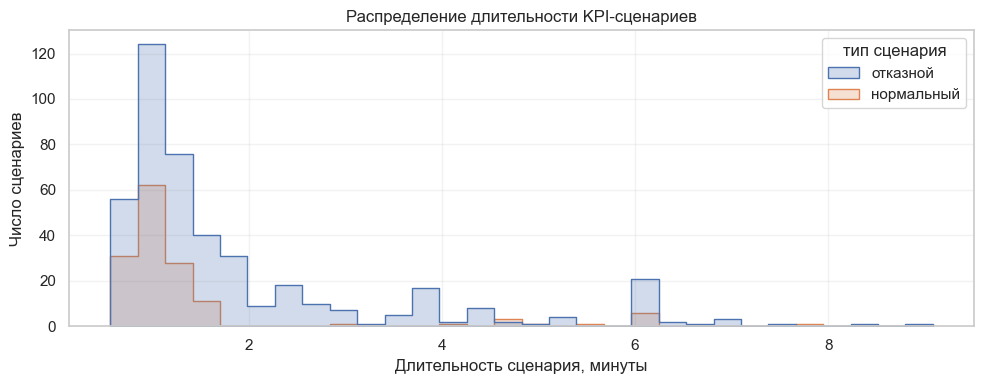

In [11]:
def build_kpi_duration_table(scenario_dirs: list[Path]) -> pd.DataFrame:
    rows = []
    for sc_dir in scenario_dirs:
        app = sc_dir.parent.name
        raw_files = [
            p
            for p in sc_dir.glob("*.csv")
            if not p.stem.endswith("-labeled") and not p.stem.endswith("-intersect")
        ]

        t_min = None
        t_max = None

        for csv_file in raw_files:
            try:
                tmp = pd.read_csv(csv_file, usecols=["timestamp"])
            except Exception:
                continue

            ts = pd.to_datetime(tmp["timestamp"], errors="coerce", utc=True).dropna()
            if ts.empty:
                continue

            local_min = ts.min()
            local_max = ts.max()
            t_min = local_min if t_min is None else min(t_min, local_min)
            t_max = local_max if t_max is None else max(t_max, local_max)

        if t_min is None or t_max is None:
            continue

        rows.append(
            {
                "scenario_id": f"{app}/{sc_dir.name}",
                "тип сценария": scenario_type(sc_dir.name),
                "duration_min": float((t_max - t_min) / pd.Timedelta(minutes=1)),
            }
        )

    return pd.DataFrame(rows)


kpi_duration_df = build_kpi_duration_table(kpi_scenario_dirs)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(
    data=kpi_duration_df,
    x="duration_min",
    hue="тип сценария",
    bins=30,
    element="step",
    stat="count",
    common_norm=False,
    ax=ax,
)
ax.set_title("Распределение длительности KPI-сценариев")
ax.set_xlabel("Длительность сценария, минуты")
ax.set_ylabel("Число сценариев")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Интерпретация результата

- **Что показано:** распределение длительностей KPI-сценариев по типам (нормальные и отказные).
- **Что наблюдается:** длительности сценариев варьируются и образуют неоднородное распределение.
- **Локальный вывод:** при оконной агрегации KPI требуется проверять устойчивость статистик к различной длине сценариев.
- **Почему это важно для ВКР:** корректные окна и нормализация KPI должны быть обоснованы фактической временной структурой данных.

In [12]:
def build_kpi_series_stats(raw_files: list[Path]) -> pd.DataFrame:
    chunks = []
    for csv_file in raw_files:
        metric = csv_file.stem
        try:
            tmp = pd.read_csv(csv_file, usecols=["series", "value"])
        except Exception:
            continue

        tmp["metric"] = metric
        chunks.append(tmp)

    values_df = pd.concat(chunks, ignore_index=True)
    values_df["value"] = pd.to_numeric(values_df["value"], errors="coerce")
    values_df = values_df.dropna(subset=["value"])

    stats_df = (
        values_df.groupby(["metric", "series"])["value"]
        .agg(
            n="size",
            q05=lambda s: s.quantile(0.05),
            median="median",
            q95=lambda s: s.quantile(0.95),
            zero_share=lambda s: (s == 0).mean(),
        )
        .reset_index()
        .sort_values(["metric", "series"])
    )
    return stats_df


kpi_series_stats_df = build_kpi_series_stats(kpi_raw_csv)
display(kpi_series_stats_df)

,metric,series,n,q05,median,q95,zero_share
0,cpu,idle,64322,28.6105,86.31,99.3000,0.001306
1,cpu,iowait,64322,0.0000,0.00,15.5400,0.514863
2,cpu,system,64322,0.2000,0.75,9.0495,0.001213
3,cpu,user,64322,0.1500,8.74,50.3000,0.001384
4,iostat,rkB_s,64322,0.0000,8.00,5900.0000,0.478468
5,iostat,util,64322,0.0000,0.80,100.0000,0.449395
6,iostat,wkB_s,64322,0.0000,8.00,167522.2000,0.483971
7,memstat,commit,64322,15.9200,22.22,26.5595,0.009888
8,memstat,memused,64322,8.5200,18.63,42.1495,0.009888
9,netstat,rxkB_s,64322,0.1000,3.00,1485.9085,0.010960


### Интерпретация результата

- **Что показано:** статистики распределений значений KPI по каждой серии (квантили, медиана, доля нулей).
- **Что наблюдается:** серии существенно различаются по масштабу и доле нулевых значений.
- **Локальный вывод:** единая ненормированная шкала признаков для KPI некорректна; необходима серия-специфичная нормализация.
- **Почему это важно для ВКР:** корректное сравнение и объединение KPI-признаков невозможно без учёта их статистической неоднородности.

## 5.1 Проверка временного разрешения KPI для оконной агрегации
Дополнительно оцениваем, сколько информативных окон формируется в отказных сценариях при разных длинах окна.

In [ ]:
window_specs = [("10 с", 10), ("30 с", 30), ("1 мин", 60), ("5 мин", 300)]
failure_duration_sec = kpi_duration_df.loc[kpi_duration_df["тип сценария"] == "отказной", "duration_min"] * 60

resolution_rows = []
for window_name, window_sec in window_specs:
    n_bins = np.ceil(failure_duration_sec / window_sec).clip(lower=1)
    resolution_rows.append(
        {
            "Окно": window_name,
            "Медиана числа окон": float(n_bins.median()),
            "Q25": float(n_bins.quantile(0.25)),
            "Q75": float(n_bins.quantile(0.75)),
            "Доля сценариев с одним окном": float((n_bins <= 1).mean()),
        }
    )

kpi_window_resolution_raw_df = pd.DataFrame(resolution_rows)
kpi_window_resolution_df = kpi_window_resolution_raw_df.copy()
for col in ["Медиана числа окон", "Q25", "Q75", "Доля сценариев с одним окном"]:
    kpi_window_resolution_df[col] = kpi_window_resolution_df[col].map(lambda x: f"{x:.3f}")

display(kpi_window_resolution_df)

### Интерпретация результата

- **Что показано:** ожидаемое число окон в отказных сценариях при разных длинах окна.
- **Что наблюдается:** при укрупнении до 5 минут значимая часть отказных сценариев схлопывается до одного окна, тогда как короткие окна сохраняют внутреннюю динамику.
- **Локальный вывод:** для KPI целесообразно использовать короткое окно (10–30 с), а для контекстных логовых признаков оставить более длинный масштаб.
- **Почему это важно для ВКР:** такое разделение уменьшает потерю информации вблизи отказа и делает признаки более содержательными.

## 5.2 KPI-покрытие на шкале логов
Проверяем, насколько равномерно KPI наблюдаются на временной шкале логов и как это связано с положительным классом.

In [ ]:
def collect_kpi_timestamps(files: list[Path]) -> pd.Series:
    chunks = []
    for csv_file in files:
        try:
            tmp = pd.read_csv(csv_file, usecols=["timestamp"])
        except Exception:
            continue

        ts = pd.to_datetime(tmp["timestamp"], errors="coerce", utc=True).dropna()
        if not ts.empty:
            chunks.append(ts)

    if not chunks:
        return pd.Series(dtype="datetime64[ns, UTC]")

    return pd.concat(chunks, ignore_index=True).drop_duplicates()


kpi_intersect_ts = collect_kpi_timestamps(kpi_intersect_csv)
freq_specs = [("10 с", "10s"), ("30 с", "30s"), ("1 мин", "1min"), ("5 мин", "5min")]

coverage_rows = []
for window_name, freq in freq_specs:
    log_window_keys = log_df["timestamp_dt"].dt.floor(freq)
    log_window_target = log_df.groupby(log_window_keys)["Label"].max()

    log_index = log_window_target.index
    pos_index = log_window_target[log_window_target == 1].index

    kpi_index = pd.DatetimeIndex(kpi_intersect_ts.dt.floor(freq).drop_duplicates())
    has_kpi = log_index.isin(kpi_index)
    pos_has_kpi = pos_index.isin(kpi_index) if len(pos_index) > 0 else np.array([])

    all_share = float(has_kpi.mean()) if len(has_kpi) > 0 else np.nan
    pos_share = float(pos_has_kpi.mean()) if len(pos_has_kpi) > 0 else np.nan
    lift = float(pos_share / all_share) if (pd.notna(all_share) and all_share > 0 and pd.notna(pos_share)) else np.nan

    coverage_rows.append(
        {
            "Окно": window_name,
            "Окон логов": int(len(log_index)),
            "Окон с Label=1": int((log_window_target == 1).sum()),
            "Доля окон с KPI": all_share,
            "Доля Label=1 окон с KPI": pos_share,
            "Лифт покрытия Label=1": lift,
        }
    )

kpi_log_coverage_raw_df = pd.DataFrame(coverage_rows)
kpi_log_coverage_df = kpi_log_coverage_raw_df.copy()
for col in ["Доля окон с KPI", "Доля Label=1 окон с KPI", "Лифт покрытия Label=1"]:
    kpi_log_coverage_df[col] = kpi_log_coverage_df[col].map(lambda x: f"{x:.3f}" if pd.notna(x) else "nan")

display(kpi_log_coverage_df)

### Интерпретация результата

- **Что показано:** доля логовых окон, в которых доступны KPI, и соответствующая доля для окон с Label=1.
- **Что наблюдается:** покрытие KPI по всей временной шкале ограничено и существенно отличается между общим фоном и положительным классом, особенно при крупном окне.
- **Локальный вывод:** при построении обучающей выборки требуется отдельно контролировать срезы по доступности KPI и избегать опоры на один лишь индикатор наличия модальности.
- **Почему это важно для ВКР:** это снижает риск смещения модели к формальному признаку доступности и сохраняет фокус на содержательной динамике KPI.

## 6. Рабочие гипотезы для дальнейшей агрегации в окнах
На основе наблюдений EDA фиксируем только проверяемые гипотезы подготовки данных.

In [13]:
top10_coverage = template_counts.head(10).sum() / template_counts.sum()
log_positive_share = rows_positive / rows_total
kpi_duration_median = float(kpi_duration_df["duration_min"].median())
one_window_share_5m = float(
    kpi_window_resolution_raw_df.loc[
        kpi_window_resolution_raw_df["Окно"] == "5 мин",
        "Доля сценариев с одним окном",
    ].iloc[0]
)
coverage_lift_5m = float(
    kpi_log_coverage_raw_df.loc[
        kpi_log_coverage_raw_df["Окно"] == "5 мин",
        "Лифт покрытия Label=1",
    ].iloc[0]
)

hypotheses_df = pd.DataFrame(
    [
        {
            "Наблюдение EDA": "Нестационарная интенсивность логов во времени",
            "Факт": "Существенная вариативность числа сообщений по минутам",
            "Гипотеза для следующего шага": "Проверить несколько длин окна (например, 30с/1м/5м)",
            "Критерий проверки": "Стабильность признаков и класса на разных длинах окна",
        },
        {
            "Наблюдение EDA": "Редкий положительный класс в логах",
            "Факт": f"Доля Label=1 на уровне строк: {log_positive_share:.4f}",
            "Гипотеза для следующего шага": "Использовать протокол оценки редких событий и контроль дисбаланса",
            "Критерий проверки": "Согласованность метрик по валидационным разбиениям",
        },
        {
            "Наблюдение EDA": "Концентрация шаблонов + редкий хвост",
            "Факт": f"Top-10 шаблонов покрывают {top10_coverage:.4f} потока",
            "Гипотеза для следующего шага": "Разделить частотное ядро и редкие шаблоны при формировании признаков",
            "Критерий проверки": "Сохранение интерпретируемости и устойчивости признаков",
        },
        {
            "Наблюдение EDA": "В логах есть дубликаты и локальные инверсии времени",
            "Факт": "Контроль качества выявил необходимость очистки и сортировки",
            "Гипотеза для следующего шага": "Ввести обязательный шаг удаление дубликатов + сортировка перед окнами",
            "Критерий проверки": "Идентичность результатов при повторном запуске пайплайна",
        },
        {
            "Наблюдение EDA": "KPI-серии неоднородны по масштабу и длительности",
            "Факт": f"Медианная длительность KPI-сценария: {kpi_duration_median:.2f} мин",
            "Гипотеза для следующего шага": "Строить признаки KPI через робастные агрегаты и серия-специфичную нормализацию",
            "Критерий проверки": "Сопоставимость распределений признаков между сценариями",
        },
        {
            "Наблюдение EDA": "Крупное окно теряет детализацию отказных KPI-сценариев",
            "Факт": f"Для окна 5 мин доля сценариев с одним окном: {one_window_share_5m:.3f}",
            "Гипотеза для следующего шага": "Разделить временные масштабы: длинный логовый контекст и короткая KPI-динамика",
            "Критерий проверки": "Прирост качества на предсбойных интервалах без потери устойчивости фоновых признаков",
        },
        {
            "Наблюдение EDA": "Покрытие KPI на шкале логов зависит от класса",
            "Факт": f"Лифт покрытия Label=1 при окне 5 мин: {coverage_lift_5m:.2f}",
            "Гипотеза для следующего шага": "Контролировать срезы по kpi_available и включать отрицательные окна с доступными KPI",
            "Критерий проверки": "Снижение разрыва метрик между срезами kpi_available=0 и kpi_available=1",
        },
    ]
)

display(hypotheses_df)

,Наблюдение EDA,Факт,Гипотеза для следующего шага,Критерий проверки
0,Нестационарная интенсивность логов во времени,Существенная вариативность числа сообщений по минутам,"Проверить несколько длин окна (например, 30с/1м/5м)",Стабильность признаков и класса на разных длинах окна
1,Редкий положительный класс в логах,Доля Label=1 на уровне строк: 0.0005,Использовать протокол оценки редких событий и контроль дисбаланса,Согласованность метрик по валидационным разбиениям
2,Концентрация шаблонов + редкий хвост,Top-10 шаблонов покрывают 0.8624 потока,Разделить частотное ядро и редкие шаблоны при формировании признаков,Сохранение интерпретируемости и устойчивости признаков
3,В логах есть дубликаты и локальные инверсии времени,Контроль качества выявил необходимость очистки и сортировки,Ввести обязательный шаг удаление дубликатов + сортировка перед окнами,Идентичность результатов при повторном запуске пайплайна
4,KPI-серии неоднородны по масштабу и длительности,Медианная длительность KPI-сценария: 1.22 мин,Строить признаки KPI через робастные агрегаты и серия-специфичную нормализацию,Сопоставимость распределений признаков между сценариями


### Интерпретация результата

- **Что показано:** рабочий набор проверяемых гипотез подготовки данных, сформированный непосредственно из EDA.
- **Что наблюдается:** гипотезы опираются на измеримые свойства данных, а не на модельные допущения.
- **Локальный вывод:** на данном этапе сформирован каркас следующего шага — оконная агрегация с раздельным контролем масштаба времени и покрытия KPI.
- **Почему это важно для ВКР:** такая фиксация обеспечивает методологическую прозрачность перехода от описания данных к построению экспериментального контура.

## 8. Reconstruction of log concatenation strategies

Цель раздела — не менять `02_multimodal_pipeline_baseline.ipynb`, а проверить, можно ли из текущего `drain_labeled.csv` восстановить логовые эпизоды и связать их с KPI-сценариями. Это именно **strategy tournament**: стратегии сравниваются не по числу найденных пар, а по балансу provenance, временной согласованности, семантической поддержки и покрытия.

Проверяемые стратегии:

| strategy | Идея проверки | Роль в выводе |
|---|---|---|
| `S0_label_transition` | текущий baseline: новый `log_run` при переходе `Label: 0→1` | нижняя граница качества |
| `S1_gap_based` | разбиение потока по временным разрывам 30/60/120/300/600 секунд | проверка естественных сегментов потока |
| `S2_application_id` | извлечение `application_*`, `appattempt_*`, `container_*` из `Content` | сильная реконструкция log episode внутри логов |
| `S3_source_file` | поиск `source_file/path` или raw log files рядом с проектом | единственный путь к строгому split, если есть provenance |
| `S4_app_name` | поиск имён приложений из `kpi_csv/` в логовом тексте | слабая semantic evidence |
| `S5_failure_family` | rule-based family по аномальным шаблонам логов и названиям KPI-сценариев | семантическая проверка отказов |
| `S6_calendar_shift` | проверка сдвигов календаря `-2d..+2d` для пар log episode × KPI scenario | диагностика смещённой временной шкалы |
| `S7_order_based` | сопоставление порядка отказов внутри app/family-групп | эвристика, когда нет явной provenance |
| `S8_relative_to_fail` | `rel_sec = timestamp - fail_start` | только диагностика/нормализация после более сильного pairing |

In [ ]:
import os
import re
from IPython.display import Markdown

TOURNAMENT_SHIFTS = np.array([-2 * 86400, -86400, 0, 86400, 2 * 86400], dtype="int64")
HORIZONS = {
    "baseline": (-3600, -900),
    "warning": (-900, -300),
    "risk": (-300, -60),
    "near_failure": (-60, 0),
    "post_failure": (0, 120),
}
GAP_THRESHOLDS_SEC = [30, 60, 120, 300, 600]


def scenario_group(name: str) -> str:
    return "normal" if str(name).lower().startswith("normal") else "failure"


def failure_family(text: str) -> str:
    """Coarse failure family shared by logs and KPI scenario names."""
    t = str(text).lower().replace("-", "_")
    if any(x in t for x in ["cpu", "user_load", "system_load"]):
        return "cpu"
    if any(x in t for x in ["io_stress", "iostat", "disk", "hdfs write", "hdfs read"]):
        return "io"
    if any(x in t for x in ["lose_package", "packet", "network", "connection", "rpc", "timeout", "inactive"]):
        return "network"
    if any(x in t for x in ["suspended", "pause", "heartbeat"]):
        return "suspended"
    if any(x in t for x in ["killed", "kill", "exitcode: 137", "exit status 143"]):
        return "killed"
    if "datanode" in t:
        return "datanode"
    if any(x in t for x in ["namenode", "name_node"]):
        return "namenode"
    if "master" in t:
        return "master"
    if any(x in t for x in ["failed", "failure", "exception", "error", "lost"]):
        return "application_failure"
    return "unknown"


def collect_kpi_scenario_timeline(scenario_dirs: list[Path]) -> pd.DataFrame:
    rows = []
    for sc_dir in scenario_dirs:
        app = sc_dir.parent.name
        csv_files = sorted(sc_dir.glob("*-labeled.csv"))
        if not csv_files:
            csv_files = sorted([p for p in sc_dir.glob("*.csv") if not p.stem.endswith("-intersect")])

        t_min = None
        t_max = None
        fail_start = None
        n_points = 0
        n_label1 = 0

        for csv_file in csv_files:
            try:
                tmp = pd.read_csv(csv_file, usecols=lambda c: c in {"timestamp", "label"})
            except Exception:
                continue

            if "timestamp" not in tmp.columns:
                continue

            ts = pd.to_datetime(tmp["timestamp"], errors="coerce", utc=True)
            ok = ts.notna()
            if not ok.any():
                continue

            ts = ts[ok]
            n_points += int(ok.sum())
            t_min = ts.min() if t_min is None else min(t_min, ts.min())
            t_max = ts.max() if t_max is None else max(t_max, ts.max())

            if "label" in tmp.columns:
                lab = pd.to_numeric(tmp.loc[ok, "label"], errors="coerce").fillna(0).astype(int)
                pos_ts = ts[lab.eq(1)]
                n_label1 += int(lab.eq(1).sum())
                if not pos_ts.empty:
                    fail_start = pos_ts.min() if fail_start is None else min(fail_start, pos_ts.min())

        if t_min is None or t_max is None:
            continue

        event_ts = fail_start if fail_start is not None else t_min
        rows.append(
            {
                "scenario_id": f"{app}/{sc_dir.name}",
                "app": app,
                "scenario": sc_dir.name,
                "scenario_group": scenario_group(sc_dir.name),
                "family": failure_family(sc_dir.name),
                "start_ts": int(t_min.timestamp()),
                "end_ts": int(t_max.timestamp()),
                "fail_start_ts": int(fail_start.timestamp()) if fail_start is not None else np.nan,
                "event_ts": int(event_ts.timestamp()),
                "duration_sec": float((t_max - t_min) / pd.Timedelta(seconds=1)),
                "n_points": int(n_points),
                "n_label1": int(n_label1),
                "has_positive": bool(n_label1 > 0),
            }
        )

    return pd.DataFrame(rows)


def scan_optional_raw_log_sources(root: Path, max_files: int = 2000, max_depth: int = 4) -> pd.DataFrame:
    """Scan nearby folders for optional raw/structured log files; prune heavy project/cache directories."""
    suffixes = {".log", ".out", ".err", ".txt", ".csv", ".json", ".jsonl"}
    name_hints = ("log", "yarn", "spark", "hadoop", "drain", "structured")
    skip_names = {".git", ".kilo", ".kilocode", "__pycache__", ".ipynb_checkpoints", "outputs", "node_modules", "kpi_csv"}
    rows = []
    seen = set()

    for base in [root, root.parent]:
        if not base.exists():
            continue
        base = base.resolve()
        for dirpath, dirnames, filenames in os.walk(base):
            current = Path(dirpath)
            try:
                rel_depth = 0 if current == base else len(current.relative_to(base).parts)
            except ValueError:
                rel_depth = max_depth
            dirnames[:] = [d for d in dirnames if d not in skip_names and rel_depth < max_depth]
            for name in filenames:
                if len(rows) >= max_files:
                    break
                p = current / name
                try:
                    resolved = p.resolve()
                except Exception:
                    continue
                if resolved in seen or resolved == LOG_PATH.resolve() or KPI_ROOT.resolve() in resolved.parents:
                    continue
                seen.add(resolved)

                name_lower = p.name.lower()
                if name_lower == "drain_labeled.csv":
                    continue
                suffix = p.suffix.lower()
                is_log_like = suffix in {".log", ".out", ".err"} or any(h in name_lower for h in name_hints)
                if suffix not in suffixes or not is_log_like:
                    continue

                try:
                    size_bytes = p.stat().st_size
                except OSError:
                    size_bytes = np.nan

                rows.append({"path": str(p), "suffix": suffix, "size_mb": np.nan if pd.isna(size_bytes) else size_bytes / 1024**2, "parent": p.parent.name})
            if len(rows) >= max_files:
                break

    return pd.DataFrame(rows).sort_values(["suffix", "path"]).reset_index(drop=True) if rows else pd.DataFrame(columns=["path", "suffix", "size_mb", "parent"])


def infer_app_scenario_from_path(path: Path) -> tuple[object, object]:
    parts = list(path.parts)
    app_names = {p.name for p in kpi_apps}
    app = next((part for part in parts if part in app_names), pd.NA)
    scenario = pd.NA
    if app is not pd.NA and app in parts:
        idx = parts.index(app)
        if idx + 1 < len(parts):
            scenario = parts[idx + 1]
    return app, scenario


def concat_raw_log_preview(raw_sources: pd.DataFrame, max_files: int = 10, max_rows_per_file: int = 200) -> pd.DataFrame:
    """Optional preview loader. pd.concat uses keys and explicit columns to preserve provenance."""
    if raw_sources.empty:
        return pd.DataFrame()

    frames = {}
    for file_order, path_str in enumerate(raw_sources["path"].head(max_files)):
        p = Path(path_str)
        app, scenario = infer_app_scenario_from_path(p)
        try:
            if p.suffix.lower() == ".csv":
                tmp = pd.read_csv(p, nrows=max_rows_per_file)
            else:
                with p.open("r", encoding="utf-8", errors="ignore") as f:
                    lines = [line.rstrip("\n") for _, line in zip(range(max_rows_per_file), f)]
                tmp = pd.DataFrame({"line_no": np.arange(len(lines)), "Content": lines})
        except Exception:
            continue

        tmp["source_path"] = str(p)
        tmp["file_order"] = file_order
        tmp["app"] = app
        tmp["scenario"] = scenario
        frames[str(p)] = tmp

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, names=["source_key", "row_in_source"]).reset_index(level=0)


kpi_scenario_timeline_df = collect_kpi_scenario_timeline(kpi_scenario_dirs)
kpi_candidates_df = kpi_scenario_timeline_df[
    (kpi_scenario_timeline_df["scenario_group"] == "failure") | kpi_scenario_timeline_df["has_positive"]
].copy()

drain_columns = pd.read_csv(LOG_PATH, nrows=0).columns.tolist()
provenance_columns = [c for c in drain_columns if re.search(r"source|file|path|app|scenario|run", c, flags=re.I)]
optional_raw_log_sources_df = scan_optional_raw_log_sources(ROOT)
raw_log_concat_preview_df = concat_raw_log_preview(optional_raw_log_sources_df)

source_audit_df = pd.DataFrame(
    [
        {"check": "drain_labeled columns", "value": ", ".join(drain_columns)},
        {"check": "potential provenance columns", "value": ", ".join(provenance_columns) if provenance_columns else "not found"},
        {"check": "optional raw log-like files", "value": int(len(optional_raw_log_sources_df))},
        {"check": "raw preview rows loaded", "value": int(len(raw_log_concat_preview_df))},
        {"check": "KPI candidates for pairing", "value": int(len(kpi_candidates_df))},
    ]
)

display(source_audit_df)
if not optional_raw_log_sources_df.empty:
    display(optional_raw_log_sources_df.head(20))
if not raw_log_concat_preview_df.empty:
    display(raw_log_concat_preview_df.head(10))

display(
    kpi_candidates_df.groupby(["scenario_group", "family"], dropna=False)
    .agg(n_scenarios=("scenario_id", "nunique"), with_label1=("has_positive", "sum"))
    .reset_index()
    .sort_values(["scenario_group", "family"])
)

### Интерпретация результата

- **Что показано:** сначала проверяется не модельная метрика, а наличие ключей восстановления: `source/path`, raw-файлы, KPI-сценарии и failure families.
- **Что наблюдать:** если `potential provenance columns = not found`, то текущий `drain_labeled.csv` уже не содержит строгого источника `source/app/scenario`; любые пары с KPI будут реконструированными или эвристическими.
- **Локальный вывод:** S3 может дать `STRICT` только при наличии явного provenance в structured logs или raw-файлах. Иначе он должен быть отклонён, даже если другие стратегии дают высокое покрытие.

In [ ]:
log_recon_df = log_df.copy()
log_recon_df["_row_order"] = np.arange(len(log_recon_df))


def mark_near_label1(timestamps: np.ndarray, label1_timestamps: np.ndarray, radius_sec: int = 300) -> np.ndarray:
    arr = np.asarray(timestamps, dtype="int64")
    ref = np.sort(np.asarray(label1_timestamps, dtype="int64"))
    if len(ref) == 0:
        return np.zeros(len(arr), dtype=bool)

    idx = np.searchsorted(ref, arr)
    left_idx = np.clip(idx - 1, 0, len(ref) - 1)
    right_idx = np.clip(idx, 0, len(ref) - 1)
    left_dist = np.where(idx > 0, np.abs(arr - ref[left_idx]), np.inf)
    right_dist = np.where(idx < len(ref), np.abs(arr - ref[right_idx]), np.inf)
    return np.minimum(left_dist, right_dist) <= radius_sec


def extract_application_key(content: pd.Series) -> pd.Series:
    text = content.fillna("").astype(str)
    app_direct = text.str.extract(r"(application_\d+_\d+)", expand=False)

    attempt_parts = text.str.extract(r"appattempt_(\d+)_(\d+)_\d+", expand=True)
    app_from_attempt = pd.Series(pd.NA, index=text.index, dtype="object")
    ok_attempt = attempt_parts.notna().all(axis=1)
    app_from_attempt.loc[ok_attempt] = "application_" + attempt_parts.loc[ok_attempt, 0] + "_" + attempt_parts.loc[ok_attempt, 1]

    container_parts = text.str.extract(r"container_(\d+)_(\d+)_\d+_\d+", expand=True)
    app_from_container = pd.Series(pd.NA, index=text.index, dtype="object")
    ok_container = container_parts.notna().all(axis=1)
    app_from_container.loc[ok_container] = "application_" + container_parts.loc[ok_container, 0] + "_" + container_parts.loc[ok_container, 1]

    return app_direct.combine_first(app_from_attempt).combine_first(app_from_container)


def compile_app_pattern(app: str):
    parts = app.split("_")
    variants = {app, app.replace("_", ""), " ".join(parts), "".join(p.capitalize() for p in parts)}
    variants = sorted({v for v in variants if len(v) >= 3}, key=len, reverse=True)
    if not variants:
        return None
    return re.compile("|".join(r"(?<![A-Za-z0-9])" + re.escape(v) + r"(?![A-Za-z0-9])" for v in variants), flags=re.I)


app_name_patterns = {}
for app_dir in kpi_apps:
    pattern = compile_app_pattern(app_dir.name)
    if pattern is not None:
        app_name_patterns[app_dir.name] = pattern


def find_kpi_app_name(text: str):
    text = "" if pd.isna(text) else str(text)
    for app, pattern in sorted(app_name_patterns.items(), key=lambda x: len(x[0]), reverse=True):
        if pattern.search(text):
            return app
    return pd.NA


label1_ts = log_recon_df.loc[log_recon_df["Label"].eq(1), "Timestamp"].to_numpy(dtype="int64")
log_recon_df["near_label1_300s"] = mark_near_label1(log_recon_df["Timestamp"].to_numpy(dtype="int64"), label1_ts, radius_sec=300)
log_recon_df["application_key"] = extract_application_key(log_recon_df["Content"])
log_recon_df["kpi_app_name"] = log_recon_df["Content"].map(find_kpi_app_name)

app_id_coverage_df = pd.DataFrame(
    [
        {
            "evidence": "application/appattempt/container id",
            "coverage_all": float(log_recon_df["application_key"].notna().mean()),
            "coverage_label1": float(log_recon_df.loc[log_recon_df["Label"].eq(1), "application_key"].notna().mean()),
            "coverage_near_label1": float(log_recon_df.loc[log_recon_df["near_label1_300s"], "application_key"].notna().mean()),
            "n_unique": int(log_recon_df["application_key"].nunique(dropna=True)),
        },
        {
            "evidence": "KPI app name in Content",
            "coverage_all": float(log_recon_df["kpi_app_name"].notna().mean()),
            "coverage_label1": float(log_recon_df.loc[log_recon_df["Label"].eq(1), "kpi_app_name"].notna().mean()),
            "coverage_near_label1": float(log_recon_df.loc[log_recon_df["near_label1_300s"], "kpi_app_name"].notna().mean()),
            "n_unique": int(log_recon_df["kpi_app_name"].nunique(dropna=True)),
        },
    ]
)

if log_recon_df["kpi_app_name"].notna().any():
    app_name_evidence_df = (
        log_recon_df.dropna(subset=["kpi_app_name"])
        .groupby("kpi_app_name")
        .agg(
            n_logs=("Timestamp", "size"),
            n_label1=("Label", "sum"),
            near_label1_logs=("near_label1_300s", "sum"),
            first_ts=("Timestamp", "min"),
            last_ts=("Timestamp", "max"),
        )
        .reset_index()
        .sort_values(["n_label1", "near_label1_logs", "n_logs"], ascending=False)
    )
else:
    app_name_evidence_df = pd.DataFrame(columns=["kpi_app_name", "n_logs", "n_label1", "near_label1_logs", "first_ts", "last_ts"])

display(app_id_coverage_df)
display(app_name_evidence_df.head(25))

### Интерпретация результата

- **Что показано:** S2 и S4 проверяются отдельно: Hadoop/Spark identifiers (`application_*`, `appattempt_*`, `container_*`) не эквивалентны именам приложений из `kpi_csv/`.
- **Что наблюдать:** высокая доля `application_key` даёт хорошее восстановление log episodes внутри логов, но не доказывает связь с конкретным KPI-сценарием. Имена app из `kpi_csv/` являются более прямой semantic evidence, но обычно встречаются реже и могут быть шумными.
- **Локальный вывод:** S2 сильнее S4 для реконструкции логовых эпизодов; S4 полезна только как дополнительная проверка app evidence.

In [ ]:
def empty_episodes() -> pd.DataFrame:
    return pd.DataFrame(
        columns=["episode_id", "start_ts", "end_ts", "fail_start_ts", "event_ts", "n_logs", "n_label1", "duration_sec", "family", "app_evidence", "app_name", "provenance"]
    )


def top_non_unknown(values) -> str:
    vals = [v for v in values if isinstance(v, str) and v not in {"", "unknown", "<NA>", "nan"}]
    return pd.Series(vals).value_counts().idxmax() if vals else "unknown"


def aggregate_grouped_episodes(
    df: pd.DataFrame,
    group_col: str,
    provenance: str,
    app_evidence: bool = False,
    app_name_col: str | None = None,
    positive_only_if_available: bool = True,
) -> pd.DataFrame:
    d = df[df[group_col].notna()].copy()
    if d.empty:
        return empty_episodes()

    d["row_family"] = d["DrainTemplate"].fillna(d["Content"]).map(failure_family)
    ep = (
        d.groupby(group_col)
        .agg(
            start_ts=("Timestamp", "min"),
            end_ts=("Timestamp", "max"),
            n_logs=("Timestamp", "size"),
            n_label1=("Label", "sum"),
            family=("row_family", top_non_unknown),
        )
        .reset_index()
        .rename(columns={group_col: "group_value"})
    )
    fail_start = d[d["Label"].eq(1)].groupby(group_col)["Timestamp"].min()
    ep["fail_start_ts"] = ep["group_value"].map(fail_start)
    if positive_only_if_available and ep["n_label1"].gt(0).any():
        ep = ep[ep["n_label1"].gt(0)].copy()
    ep["duration_sec"] = (ep["end_ts"] - ep["start_ts"]).clip(lower=0)
    ep["event_ts"] = ep["fail_start_ts"].fillna(ep["start_ts"]).astype("int64")
    ep["episode_id"] = provenance + ":" + ep["group_value"].astype(str)
    ep["app_evidence"] = bool(app_evidence)
    ep["app_name"] = ep["group_value"] if app_name_col == group_col else pd.NA
    ep["provenance"] = provenance
    return ep.drop(columns=["group_value"])


def build_label_transition_episodes(df: pd.DataFrame, prefix: str = "S0") -> pd.DataFrame:
    s = df.sort_values(["Timestamp", "_row_order"]).reset_index(drop=True).copy()
    positive = s["Label"].eq(1)
    if not positive.any():
        return empty_episodes()
    s["episode_seq"] = (positive & ~positive.shift(fill_value=False)).cumsum()
    ep = (
        s[positive]
        .groupby("episode_seq")
        .agg(
            start_ts=("Timestamp", "min"),
            end_ts=("Timestamp", "max"),
            fail_start_ts=("Timestamp", "min"),
            n_logs=("Timestamp", "size"),
            n_label1=("Label", "sum"),
            templates=("DrainTemplate", lambda x: " || ".join(pd.Series(x).dropna().astype(str).head(8))),
        )
        .reset_index(drop=True)
    )
    ep["duration_sec"] = (ep["end_ts"] - ep["start_ts"]).clip(lower=0)
    ep["event_ts"] = ep["fail_start_ts"].astype("int64")
    ep["episode_id"] = [f"{prefix}_{i:04d}" for i in range(len(ep))]
    ep["family"] = ep["templates"].map(failure_family)
    ep["app_evidence"] = False
    ep["app_name"] = pd.NA
    ep["provenance"] = "label_transition"
    return ep.drop(columns=["templates"])


def build_gap_episodes(df: pd.DataFrame, threshold_sec: int) -> pd.DataFrame:
    s = df.sort_values(["Timestamp", "_row_order"]).reset_index(drop=True).copy()
    s["segment_id"] = s["Timestamp"].diff().fillna(0).gt(threshold_sec).cumsum()
    ep = aggregate_grouped_episodes(s, "segment_id", f"gap>{threshold_sec}s", positive_only_if_available=True)
    if not ep.empty:
        ep["episode_id"] = [f"S1_gap{threshold_sec}_{i:04d}" for i in range(len(ep))]
    return ep


def build_source_file_episodes_from_drain(provenance_cols: list[str]) -> tuple[pd.DataFrame, float, bool]:
    if not provenance_cols:
        return empty_episodes(), 0.0, False
    usecols = list(dict.fromkeys(["Timestamp", "Content", "DrainTemplate", "Label"] + provenance_cols))
    try:
        d = pd.read_csv(LOG_PATH, usecols=usecols)
    except Exception:
        return empty_episodes(), 0.0, False
    d["Timestamp"] = pd.to_numeric(d["Timestamp"], errors="coerce")
    d["Label"] = pd.to_numeric(d["Label"], errors="coerce").fillna(0).astype(int)
    d = d.dropna(subset=["Timestamp"]).copy()
    d["Timestamp"] = d["Timestamp"].astype("int64")
    source_cols = [c for c in provenance_cols if re.search(r"source|file|path", c, flags=re.I)]
    app_cols = [c for c in provenance_cols if re.search(r"app|application", c, flags=re.I)]
    scenario_cols = [c for c in provenance_cols if re.search(r"scenario|run", c, flags=re.I)]
    group_cols = source_cols[:1] + app_cols[:1] + scenario_cols[:1]
    if not group_cols:
        group_cols = provenance_cols[:1]
    d["source_group"] = d[group_cols].astype(str).agg(" | ".join, axis=1)
    strict = bool(source_cols and (app_cols or scenario_cols))
    score = 0.85 if strict else (0.60 if source_cols else 0.30)
    ep = aggregate_grouped_episodes(d, "source_group", "source_file", app_evidence=bool(app_cols), positive_only_if_available=True)
    return ep, score, strict


def overlap_array(a_start, a_end, b_start, b_end):
    return np.maximum(0, np.minimum(a_end, b_end) - np.maximum(a_start, b_start))


def overlap_scalar(a_start, a_end, b_start, b_end) -> float:
    return float(max(0, min(a_end, b_end) - max(a_start, b_start)))


def make_pair_frame(episodes: pd.DataFrame, kpi: pd.DataFrame, episode_idx: np.ndarray, kpi_idx: np.ndarray, shifts: np.ndarray) -> pd.DataFrame:
    e = episodes.reset_index(drop=True)
    k = kpi.reset_index(drop=True)
    e_event = e.loc[episode_idx, "event_ts"].to_numpy(dtype="int64")
    k_event = k.loc[kpi_idx, "event_ts"].to_numpy(dtype="int64")
    deltas = e_event[:, None] - (k_event[:, None] + shifts[None, :])
    best_pos = np.argmin(np.abs(deltas), axis=1)
    shifted_delta = deltas[np.arange(len(deltas)), best_pos]
    best_shift = shifts[best_pos]
    pair = pd.DataFrame(
        {
            "episode_i": episode_idx,
            "kpi_i": kpi_idx,
            "episode_id": e.loc[episode_idx, "episode_id"].astype(str).to_numpy(),
            "scenario_id": k.loc[kpi_idx, "scenario_id"].astype(str).to_numpy(),
            "raw_delta_sec": (e_event - k_event).astype(float),
            "shifted_delta_sec": shifted_delta.astype(float),
            "best_shift_sec": best_shift.astype(int),
            "overlap_sec": overlap_array(
                e.loc[episode_idx, "start_ts"].to_numpy(dtype="int64"),
                e.loc[episode_idx, "end_ts"].to_numpy(dtype="int64"),
                k.loc[kpi_idx, "start_ts"].to_numpy(dtype="int64") + best_shift,
                k.loc[kpi_idx, "end_ts"].to_numpy(dtype="int64") + best_shift,
            ).astype(float),
            "log_family": e.loc[episode_idx, "family"].astype(str).to_numpy(),
            "kpi_family": k.loc[kpi_idx, "family"].astype(str).to_numpy(),
            "app_name": e.loc[episode_idx, "app_name"].astype(str).to_numpy(),
            "kpi_app": k.loc[kpi_idx, "app"].astype(str).to_numpy(),
            "app_evidence": e.loc[episode_idx, "app_evidence"].fillna(False).astype(bool).to_numpy(),
        }
    )
    pair["family_match"] = pair["log_family"].eq(pair["kpi_family"]) & ~pair["log_family"].isin(["unknown", "<NA>", "nan"])
    pair["app_match"] = pair["app_name"].eq(pair["kpi_app"]) & ~pair["app_name"].isin(["<NA>", "nan", "None"])
    return pair


def pair_nearest(episodes: pd.DataFrame, kpi: pd.DataFrame, shifts: np.ndarray = TOURNAMENT_SHIFTS, semantic_mode: str | None = None, max_abs_shifted_sec: int = 3600) -> pd.DataFrame:
    if episodes is None or episodes.empty or kpi.empty:
        return pd.DataFrame()
    e = episodes.reset_index(drop=True)
    k = kpi.reset_index(drop=True)
    episode_idx = np.repeat(np.arange(len(e)), len(k))
    kpi_idx = np.tile(np.arange(len(k)), len(e))
    pair = make_pair_frame(e, k, episode_idx, kpi_idx, shifts)
    semantic_bonus = np.zeros(len(pair))
    if semantic_mode in {"family", "family_app"}:
        semantic_bonus += pair["family_match"].to_numpy(dtype=float) * 1800
    if semantic_mode in {"app", "family_app"}:
        semantic_bonus += pair["app_match"].to_numpy(dtype=float) * 3600
    pair["pair_score"] = pair["shifted_delta_sec"].abs().to_numpy() - semantic_bonus - np.minimum(pair["overlap_sec"].to_numpy(), 3600)
    best = pair.loc[pair.groupby("episode_i")["pair_score"].idxmin()].copy()
    best["is_match"] = best["shifted_delta_sec"].abs().le(max_abs_shifted_sec) | best["overlap_sec"].gt(0) | best["family_match"] | best["app_match"]
    return best[best["is_match"]].copy()


def pair_by_order_family(episodes: pd.DataFrame, kpi: pd.DataFrame) -> pd.DataFrame:
    if episodes.empty or kpi.empty:
        return pd.DataFrame()
    e = episodes.reset_index(drop=True)
    k = kpi.reset_index(drop=True)
    frames = []
    for fam in sorted((set(e["family"]) & set(k["family"])) - {"unknown"}):
        e_idx = e[e["family"].eq(fam)].sort_values("event_ts").index.to_numpy()
        k_idx = k[k["family"].eq(fam)].sort_values("event_ts").index.to_numpy()
        n = min(len(e_idx), len(k_idx))
        if n:
            frames.append(make_pair_frame(e, k, e_idx[:n], k_idx[:n], TOURNAMENT_SHIFTS))
    if not frames:
        n = min(len(e), len(k))
        frames.append(make_pair_frame(e, k, e.sort_values("event_ts").index.to_numpy()[:n], k.sort_values("event_ts").index.to_numpy()[:n], TOURNAMENT_SHIFTS))
    pairs = pd.concat(frames, ignore_index=True)
    pairs["pair_score"] = pairs["shifted_delta_sec"].abs() - pairs["family_match"].astype(float) * 1800
    pairs["is_match"] = True
    return pairs


def finite_mean(values) -> float:
    values = [v for v in values if pd.notna(v)]
    return float(np.mean(values)) if values else 0.0


def summarize_strategy(strategy: str, episodes: pd.DataFrame, pairs: pd.DataFrame, kpi: pd.DataFrame, provenance_score: float, strict_split_possible: bool = False, verdict_hint: str | None = None) -> dict:
    n_log_episodes = 0 if episodes is None else int(len(episodes))
    n_kpi_candidates = int(len(kpi))
    matched_pairs = 0 if pairs is None else int(len(pairs))
    unique_kpi = 0 if pairs is None or pairs.empty else int(pairs["scenario_id"].nunique())
    median_abs_delta = np.nan if pairs is None or pairs.empty else float(pairs["raw_delta_sec"].abs().median())
    median_shifted_abs_delta = np.nan if pairs is None or pairs.empty else float(pairs["shifted_delta_sec"].abs().median())
    max_overlap = 0.0 if pairs is None or pairs.empty else float(pairs["overlap_sec"].max())
    family_match_rate = np.nan if pairs is None or pairs.empty else float(pairs["family_match"].mean())
    app_evidence_rate = np.nan if pairs is None or pairs.empty else float((pairs["app_evidence"] | pairs["app_match"]).mean())
    coverage_score = float(unique_kpi / n_kpi_candidates) if n_kpi_candidates else 0.0
    temporal_score = 0.0 if not np.isfinite(median_shifted_abs_delta) else max(0.0, 1.0 - min(median_shifted_abs_delta, 7200) / 7200)
    if max_overlap > 0:
        temporal_score = max(temporal_score, min(1.0, max_overlap / 600))
    semantic_score = finite_mean([0.0 if pd.isna(family_match_rate) else family_match_rate, 0.0 if pd.isna(app_evidence_rate) else app_evidence_rate])
    final_score = 0.40 * provenance_score + 0.25 * temporal_score + 0.25 * semantic_score + 0.10 * coverage_score

    horizon_coverage = {h: 0.0 for h in HORIZONS}
    if pairs is not None and not pairs.empty and episodes is not None and not episodes.empty:
        e_index = episodes.set_index("episode_id")
        k_index = kpi.set_index("scenario_id")
        covered = {h: set() for h in HORIZONS}
        for _, row in pairs.iterrows():
            if row["episode_id"] not in e_index.index or row["scenario_id"] not in k_index.index:
                continue
            ep = e_index.loc[row["episode_id"]]
            kp = k_index.loc[row["scenario_id"]]
            shifted_kpi_event = int(kp["event_ts"]) + int(row["best_shift_sec"])
            for h_name, (h_start, h_end) in HORIZONS.items():
                if overlap_scalar(int(ep["start_ts"]), int(ep["end_ts"]), shifted_kpi_event + h_start, shifted_kpi_event + h_end) > 0:
                    covered[h_name].add(row["scenario_id"])
        horizon_coverage = {h: (len(v) / n_kpi_candidates if n_kpi_candidates else 0.0) for h, v in covered.items()}

    if verdict_hint is not None:
        verdict = verdict_hint
    elif n_log_episodes == 0 or matched_pairs == 0:
        verdict = "REJECTED"
    elif strict_split_possible and provenance_score >= 0.80:
        verdict = "STRICT"
    elif final_score >= 0.45 and provenance_score >= 0.50:
        verdict = "RECONSTRUCTED"
    elif final_score >= 0.20:
        verdict = "HEURISTIC_ONLY"
    else:
        verdict = "DIAGNOSTIC_ONLY"

    return {
        "strategy": strategy,
        "n_log_episodes": n_log_episodes,
        "n_kpi_candidates": n_kpi_candidates,
        "matched_pairs": matched_pairs,
        "median_abs_delta_sec": median_abs_delta,
        "median_shifted_abs_delta_sec": median_shifted_abs_delta,
        "max_overlap_sec": max_overlap,
        "family_match_rate": family_match_rate,
        "app_evidence_rate": app_evidence_rate,
        "kpi_coverage_by_horizon": horizon_coverage,
        "strict_split_possible": bool(strict_split_possible),
        "provenance_score": float(provenance_score),
        "temporal_score": float(temporal_score),
        "semantic_score": float(semantic_score),
        "coverage_score": float(coverage_score),
        "final_strategy_score": float(final_score),
        "verdict": verdict,
    }


def build_relative_to_fail_table(df: pd.DataFrame) -> pd.DataFrame:
    s = df.sort_values(["Timestamp", "_row_order"]).reset_index(drop=True).copy()
    positive = s["Label"].eq(1)
    s["label_run"] = (positive & ~positive.shift(fill_value=False)).cumsum()
    rel = s[positive].copy()
    rel["fail_start"] = rel.groupby("label_run")["Timestamp"].transform("min")
    rel["rel_sec"] = rel["Timestamp"] - rel["fail_start"]
    return rel[["Timestamp", "Content", "DrainTemplate", "Label", "label_run", "fail_start", "rel_sec"]]


strategy_rows = []
pairs_by_strategy = {}
episodes_by_strategy = {}

s0_episodes = build_label_transition_episodes(log_recon_df, prefix="S0")
s0_pairs = pair_nearest(s0_episodes, kpi_candidates_df, semantic_mode=None, max_abs_shifted_sec=3600)
episodes_by_strategy["S0_label_transition"] = s0_episodes
pairs_by_strategy["S0_label_transition"] = s0_pairs
strategy_rows.append(summarize_strategy("S0_label_transition", s0_episodes, s0_pairs, kpi_candidates_df, provenance_score=0.10))

gap_variant_rows = []
for gap_sec in GAP_THRESHOLDS_SEC:
    ep = build_gap_episodes(log_recon_df, gap_sec)
    pairs = pair_nearest(ep, kpi_candidates_df, semantic_mode=None, max_abs_shifted_sec=3600)
    row = summarize_strategy(f"S1_gap_based_{gap_sec}s", ep, pairs, kpi_candidates_df, provenance_score=0.20)
    row["gap_threshold_sec"] = gap_sec
    gap_variant_rows.append(row)
gap_variant_df = pd.DataFrame(gap_variant_rows).sort_values("final_strategy_score", ascending=False)
best_gap_row = gap_variant_df.iloc[0].to_dict() if not gap_variant_df.empty else summarize_strategy("S1_gap_based", empty_episodes(), pd.DataFrame(), kpi_candidates_df, 0.20)
best_gap_row["strategy"] = "S1_gap_based"
best_gap_row["selected_variant"] = f"{int(best_gap_row.get('gap_threshold_sec', np.nan))}s" if pd.notna(best_gap_row.get("gap_threshold_sec", np.nan)) else pd.NA
strategy_rows.append(best_gap_row)

s2_episodes = aggregate_grouped_episodes(log_recon_df, "application_key", "application_id", app_evidence=True, positive_only_if_available=True)
s2_pairs = pair_nearest(s2_episodes, kpi_candidates_df, semantic_mode=None, max_abs_shifted_sec=3600)
episodes_by_strategy["S2_application_id"] = s2_episodes
pairs_by_strategy["S2_application_id"] = s2_pairs
strategy_rows.append(summarize_strategy("S2_application_id", s2_episodes, s2_pairs, kpi_candidates_df, provenance_score=0.70))

s3_episodes, s3_score, s3_strict = build_source_file_episodes_from_drain(provenance_columns)
s3_pairs = pair_nearest(s3_episodes, kpi_candidates_df, semantic_mode=None, max_abs_shifted_sec=3600)
episodes_by_strategy["S3_source_file"] = s3_episodes
pairs_by_strategy["S3_source_file"] = s3_pairs
strategy_rows.append(summarize_strategy("S3_source_file", s3_episodes, s3_pairs, kpi_candidates_df, provenance_score=s3_score, strict_split_possible=s3_strict))

s4_episodes = aggregate_grouped_episodes(log_recon_df, "kpi_app_name", "app_name", app_evidence=True, app_name_col="kpi_app_name", positive_only_if_available=False)
s4_pairs = pair_nearest(s4_episodes, kpi_candidates_df, semantic_mode="app", max_abs_shifted_sec=3600)
episodes_by_strategy["S4_app_name"] = s4_episodes
pairs_by_strategy["S4_app_name"] = s4_pairs
strategy_rows.append(summarize_strategy("S4_app_name", s4_episodes, s4_pairs, kpi_candidates_df, provenance_score=0.35))

s5_episodes = s0_episodes.copy()
s5_episodes["episode_id"] = [f"S5_{i:04d}" for i in range(len(s5_episodes))]
s5_pairs = pair_nearest(s5_episodes, kpi_candidates_df, semantic_mode="family", max_abs_shifted_sec=3600)
episodes_by_strategy["S5_failure_family"] = s5_episodes
pairs_by_strategy["S5_failure_family"] = s5_pairs
strategy_rows.append(summarize_strategy("S5_failure_family", s5_episodes, s5_pairs, kpi_candidates_df, provenance_score=0.25))

s6_episodes = s0_episodes.copy()
s6_episodes["episode_id"] = [f"S6_{i:04d}" for i in range(len(s6_episodes))]
s6_pairs = pair_nearest(s6_episodes, kpi_candidates_df, semantic_mode=None, max_abs_shifted_sec=7200)
episodes_by_strategy["S6_calendar_shift"] = s6_episodes
pairs_by_strategy["S6_calendar_shift"] = s6_pairs
strategy_rows.append(summarize_strategy("S6_calendar_shift", s6_episodes, s6_pairs, kpi_candidates_df, provenance_score=0.15))

s7_episodes = s5_episodes.copy()
s7_episodes["episode_id"] = [f"S7_{i:04d}" for i in range(len(s7_episodes))]
s7_pairs = pair_by_order_family(s7_episodes, kpi_candidates_df)
episodes_by_strategy["S7_order_based"] = s7_episodes
pairs_by_strategy["S7_order_based"] = s7_pairs
strategy_rows.append(summarize_strategy("S7_order_based", s7_episodes, s7_pairs, kpi_candidates_df, provenance_score=0.20))

relative_to_fail_df = build_relative_to_fail_table(log_recon_df)
relative_to_fail_summary_df = relative_to_fail_df.groupby("label_run")["rel_sec"].agg(n_label1="size", min_rel_sec="min", median_rel_sec="median", max_rel_sec="max").reset_index()
strategy_rows.append(summarize_strategy("S8_relative_to_fail", s0_episodes, pd.DataFrame(), kpi_candidates_df, provenance_score=0.05, verdict_hint="DIAGNOSTIC_ONLY"))

strategy_tournament_df = pd.DataFrame(strategy_rows)
for horizon_name in HORIZONS:
    strategy_tournament_df[f"kpi_coverage_{horizon_name}"] = strategy_tournament_df["kpi_coverage_by_horizon"].map(lambda d: d.get(horizon_name, np.nan) if isinstance(d, dict) else np.nan)

priority_rank = {"S3_source_file_strict": 1, "S2_application_id": 2, "S3_source_file": 3, "S7_order_based": 4, "S5_failure_family": 5, "S6_calendar_shift": 5, "S8_relative_to_fail": 6, "S0_label_transition": 7, "S1_gap_based": 8, "S4_app_name": 9}


def selection_priority(row) -> int:
    if row["strategy"] == "S3_source_file" and row["strict_split_possible"]:
        return priority_rank["S3_source_file_strict"]
    return priority_rank.get(row["strategy"], 99)


strategy_tournament_df["selection_priority"] = strategy_tournament_df.apply(selection_priority, axis=1)
eligible = strategy_tournament_df[~strategy_tournament_df["verdict"].eq("REJECTED")].copy()
recommended_row = eligible.sort_values(["selection_priority", "final_strategy_score"], ascending=[True, False]).iloc[0] if not eligible.empty else strategy_tournament_df.sort_values("final_strategy_score", ascending=False).iloc[0]
recommended_concat_strategy = recommended_row["strategy"]
if recommended_concat_strategy == "S2_application_id" and "S6_calendar_shift" in strategy_tournament_df["strategy"].values:
    recommended_concat_strategy = "S2_application_id + S6_calendar_shift audit"

score_cols = ["provenance_score", "temporal_score", "semantic_score", "coverage_score", "final_strategy_score"]
metric_cols = ["strategy", "n_log_episodes", "n_kpi_candidates", "matched_pairs", "median_abs_delta_sec", "median_shifted_abs_delta_sec", "max_overlap_sec", "family_match_rate", "app_evidence_rate", "kpi_coverage_by_horizon", "strict_split_possible", *score_cols, "selection_priority", "verdict"]
strategy_display_df = strategy_tournament_df[metric_cols].copy()
for col in ["median_abs_delta_sec", "median_shifted_abs_delta_sec", "max_overlap_sec", *score_cols, "family_match_rate", "app_evidence_rate"]:
    strategy_display_df[col] = strategy_display_df[col].map(lambda x: np.nan if pd.isna(x) else round(float(x), 4))

gap_display_df = gap_variant_df[["strategy", "gap_threshold_sec", "n_log_episodes", "matched_pairs", "median_shifted_abs_delta_sec", "coverage_score", "final_strategy_score", "verdict"]].copy()
for col in ["median_shifted_abs_delta_sec", "coverage_score", "final_strategy_score"]:
    gap_display_df[col] = gap_display_df[col].map(lambda x: np.nan if pd.isna(x) else round(float(x), 4))

if not pairs_by_strategy.get("S6_calendar_shift", pd.DataFrame()).empty:
    calendar_shift_distribution_df = (
        pairs_by_strategy["S6_calendar_shift"]
        .assign(best_shift_days=lambda x: x["best_shift_sec"] / 86400)
        .groupby("best_shift_days")
        .agg(n_pairs=("scenario_id", "size"), median_abs_shifted_delta_sec=("shifted_delta_sec", lambda s: float(s.abs().median())))
        .reset_index()
    )
else:
    calendar_shift_distribution_df = pd.DataFrame(columns=["best_shift_days", "n_pairs", "median_abs_shifted_delta_sec"])

recommended_df = pd.DataFrame(
    [
        {
            "recommended_concat_strategy": recommended_concat_strategy,
            "source_strategy": recommended_row["strategy"],
            "verdict": recommended_row["verdict"],
            "strict_split_possible": bool(recommended_row["strict_split_possible"]),
            "final_strategy_score": round(float(recommended_row["final_strategy_score"]), 4),
            "selection_priority": int(recommended_row["selection_priority"]),
        }
    ]
)

display(gap_display_df)
display(strategy_display_df.sort_values(["selection_priority", "final_strategy_score"], ascending=[True, False]))
display(calendar_shift_distribution_df)
display(relative_to_fail_summary_df.head(10))
display(recommended_df)

### Интерпретация результата

- **Что показано:** каждая стратегия получает один и тот же набор метрик: размер восстановленных log episodes, число KPI-кандидатов, пары, временные дельты, overlap, family/app evidence, покрытие KPI по горизонтам и итоговый verdict.
- **Что наблюдать:** `final_strategy_score` не максимизирует покрытие; вес покрытия намеренно мал, а выбор `recommended_concat_strategy` дополнительно упорядочен по приоритету `explicit provenance → application_id → source_file → order+family+shift → relative_only → label_transition`.
- **Локальный вывод:** стратегия с высоким coverage, но без provenance и semantics, остаётся эвристикой. Для полноценного multimodal pipeline нужен `STRICT` или как минимум устойчивый `RECONSTRUCTED` с понятной причиной реконструкции.

In [ ]:
source_missing = not provenance_columns
raw_missing = optional_raw_log_sources_df.empty
app_id_row = app_id_coverage_df.loc[app_id_coverage_df["evidence"].eq("application/appattempt/container id")].iloc[0]
app_name_row = app_id_coverage_df.loc[app_id_coverage_df["evidence"].eq("KPI app name in Content")].iloc[0]
strict_available = bool(strategy_tournament_df["strict_split_possible"].any())
recommended_verdict = str(recommended_row["verdict"])

if strict_available and recommended_verdict == "STRICT":
    full_pipeline_answer = "да: есть явная provenance-связка, поэтому 02 можно строить как полноценный paired multimodal pipeline"
else:
    full_pipeline_answer = "нет как строгий paired pipeline: допустим только reconstructed/diagnostic режим с явным контролем слабой связки"

lost_source_signs = []
if source_missing:
    lost_source_signs.append("в `drain_labeled.csv` нет `source/path/app/scenario` колонок")
if raw_missing:
    lost_source_signs.append("рядом с проектом не найдены raw log-like файлы для восстановления provenance")
elif source_missing:
    lost_source_signs.append("raw log-like файлы найдены, но `drain_labeled.csv` не хранит `source_path`, поэтому обратная привязка потеряна")
if float(app_id_row["coverage_label1"]) > 0 and float(app_id_row["coverage_label1"]) < 0.20:
    lost_source_signs.append("application/container id покрывает только небольшую часть Label=1")
if float(app_name_row["coverage_label1"]) < 0.05:
    lost_source_signs.append("имена app из `kpi_csv/` почти не встречаются в Label=1")

lost_source_answer = "; ".join(lost_source_signs) if lost_source_signs else "явных признаков потери provenance не обнаружено"
diagnostic_mode = (
    "Допустимый режим: log episodes строить по `S2_application_id`, если нужен устойчивый log-level episode; "
    "календарные сдвиги из `S6` использовать только как audit; `S8_relative_to_fail` применять как нормализацию внутри уже найденного episode, "
    "а не как самостоятельный способ связать logs и KPI. KPI можно использовать для scenario-level diagnostics, coverage slices и sanity-check графиков, "
    "но не как источник строгих paired targets без provenance."
)

conclusion_md = f"""
### Итог раздела 8

1. **Лучшая стратегия конкатенации логов для объяснения KPI:** `{recommended_concat_strategy}`. Она выбрана по приоритету provenance/semantics, а не по максимальному coverage. Текущий verdict: **{recommended_verdict}**.
2. **Признаки потери `source/app/scenario` в `drain_labeled.csv`:** {lost_source_answer}.
3. **Можно ли строить `02` как полноценный multimodal pipeline:** {full_pipeline_answer}.
4. **Если строгий pipeline нельзя строить, допустимый diagnostic режим:** {diagnostic_mode}
"""

Markdown(conclusion_md)

## Итог EDA

Разведочный анализ показал, что исходные данные обладают следующими ключевыми свойствами:

1. Логовый и KPI-источники структурно различны и требуют согласованной, но раздельной предобработки.
2. Логи характеризуются нестационарным потоком и редкими аномальными событиями.
3. Словарь логовых шаблонов имеет концентрированное частотное ядро и редкий хвост, при этом аномальные шаблоны интерпретируемы.
4. KPI-контур организован регулярно по метрикам, но неоднороден по диапазонам значений, длительности сценариев и временной плотности покрытия на шкале логов.
5. Для отказных KPI-сценариев крупные окна существенно теряют детализацию, тогда как короткие окна сохраняют динамику предсбойного участка.
6. Восстановление log episodes должно начинаться с проверки provenance; без `source/app/scenario` связка logs↔KPI остаётся реконструированной или диагностической, а не строгой paired-разметкой.

Следующий этап после данного EDA — построение и валидация оконной агрегации с раздельным контролем временного масштаба, покрытия KPI и качества реконструкции log↔KPI pairing, без преждевременных выводов о качестве конкретных моделей.